In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm

# Load the dataset
df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")

df['Combined_Features'] = df['Combined_Features'].apply(eval)
X = np.array(df['Combined_Features'].tolist())
y = df['Class_Label'].values

# Define the objective function for feature selection
def objective_function(mask):
    selected_features = np.where(mask > 0.5)[0]
    if len(selected_features) == 0:
        return 1.0
    X_selected = X[:, selected_features]
    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)
    clf = RandomForestClassifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    return 1 - accuracy

# Define the Bat Algorithm for feature selection
class BatAlgorithm:
    def __init__(self, obj_func, dim, bounds, population_size=20, max_iter=100, f_min=0, f_max=2):
        self.obj_func = obj_func
        self.dim = dim
        self.bounds = bounds
        self.population_size = population_size
        self.max_iter = max_iter
        self.f_min = f_min
        self.f_max = f_max
        
        # Initialize bat positions and velocities
        self.population = np.random.uniform(bounds[0], bounds[1], (population_size, dim))
        self.velocity = np.zeros((population_size, dim))
        self.frequencies = np.random.uniform(f_min, f_max, population_size)
        self.loudness = np.ones(population_size)
        self.pulse_rate = np.ones(population_size)
        self.fitness = np.array([obj_func(ind) for ind in self.population])
        self.best_idx = np.argmin(self.fitness)
        self.best_solution = self.population[self.best_idx]
        self.best_fitness = self.fitness[self.best_idx]

    def optimize(self):
        for iteration in tqdm(range(self.max_iter), desc="Optimizing"):
            for i in range(self.population_size):
                # Adjust frequency
                self.frequencies[i] = self.f_min + (self.f_max - self.f_min) * np.random.rand()
                self.velocity[i] += (self.population[i] - self.best_solution) * self.frequencies[i]
                new_solution = self.population[i] + self.velocity[i]
                new_solution = np.clip(new_solution, self.bounds[0], self.bounds[1])

                # Pulse rate & loudness check
                if np.random.rand() > self.pulse_rate[i]:
                    new_solution = self.best_solution + np.random.uniform(-1, 1, self.dim) * np.mean(self.loudness)
                
                new_fitness = self.obj_func(new_solution)
                if new_fitness < self.fitness[i] and np.random.rand() < self.loudness[i]:
                    self.population[i] = new_solution
                    self.fitness[i] = new_fitness
                    self.loudness[i] *= 0.9
                    self.pulse_rate[i] = 1 - np.exp(-0.1 * iteration)

                if new_fitness < self.best_fitness:
                    self.best_solution = new_solution
                    self.best_fitness = new_fitness

        return self.best_solution, self.best_fitness

# Set parameters
dim = X.shape[1]
bounds = [0, 1]
max_iter = 100
population_size = 20

# Initialize and run the optimizer
bat_optimizer = BatAlgorithm(objective_function, dim, bounds, population_size=population_size, max_iter=max_iter)
best_mask, best_fitness = bat_optimizer.optimize()

# Extract the selected features
selected_features = np.where(best_mask > 0.5)[0]
df['Selected_Features'] = df['Combined_Features'].apply(lambda x: [x[i] for i in selected_features])

# Save the new CSV
df[['Image_Index', 'Class_Label', 'Selected_Features']].to_csv('BAT_selected_features.csv', index=False)

print("Feature selection completed with Bat Algorithm and new dataset saved!")

Optimizing: 100%|██████████| 100/100 [08:02<00:00,  4.83s/it]

Feature selection completed with Bat Algorithm and new dataset saved!


In [3]:
import pandas as pd

# Load original and selected datasets
original_df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")
selected_df = pd.read_csv('BAT_selected_features.csv')

# Extract and count features
original_features_count = len(eval(original_df['Combined_Features'][0]))
selected_features_count = len(eval(selected_df['Selected_Features'][0]))

# Compare number of features
print(f"Original number of features: {original_features_count}")
print(f"Selected number of features: {selected_features_count}")

reduction_percentage = ((original_features_count - selected_features_count) / original_features_count) * 100
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original number of features: 199
Selected number of features: 97
Feature reduction: 51.26%


# ML

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, MaxPooling1D, Dropout
import matplotlib.pyplot as plt
import seaborn as sns

# Load CSV
data = pd.read_csv("BAT_selected_features.csv")

# Parse features
features = data['Selected_Features'].apply(lambda x: np.array(eval(x))).tolist()
X = np.array(features)
y = data['Class_Label']

# Encode class labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Helper function to evaluate models
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted'))
    print("Recall:", recall_score(y_test, y_pred, average='weighted'))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.show()

Accuracy: 0.7927461139896373
Precision: 0.7988910670890991
Recall: 0.7927461139896373
F1 Score: 0.7902574516755487
Confusion Matrix:
 [[33  2  2  0  3  0]
 [ 1 23  0  0  3  0]
 [11  0 19  2  1  0]
 [ 0  0  1 32  0  0]
 [ 1  0  1  0 20  8]
 [ 1  0  0  0  3 26]]


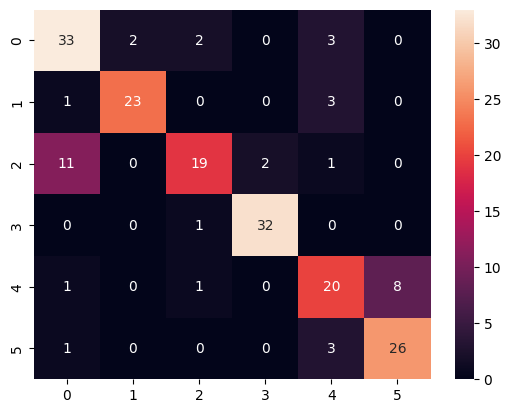

In [2]:
# 1. Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
evaluate_model(nb_model, X_test, y_test)

Accuracy: 0.9430051813471503
Precision: 0.9442467944891478
Recall: 0.9430051813471503
F1 Score: 0.9432594825497311
Confusion Matrix:
 [[39  0  1  0  0  0]
 [ 0 26  0  0  1  0]
 [ 3  0 30  0  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  0  0 28  2]
 [ 0  0  0  0  2 28]]


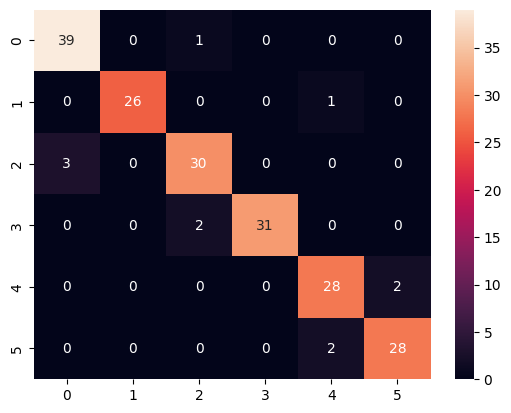

In [3]:
# 2. Support Vector Machine
svm_model = SVC()
svm_model.fit(X_train, y_train)
evaluate_model(svm_model, X_test, y_test)

Accuracy: 0.8134715025906736
Precision: 0.81415810404612
Recall: 0.8134715025906736
F1 Score: 0.8130443572823524
Confusion Matrix:
 [[31  3  6  0  0  0]
 [ 2 22  2  0  1  0]
 [ 7  1 21  3  1  0]
 [ 0  0  1 32  0  0]
 [ 2  1  1  0 25  1]
 [ 0  0  0  0  4 26]]


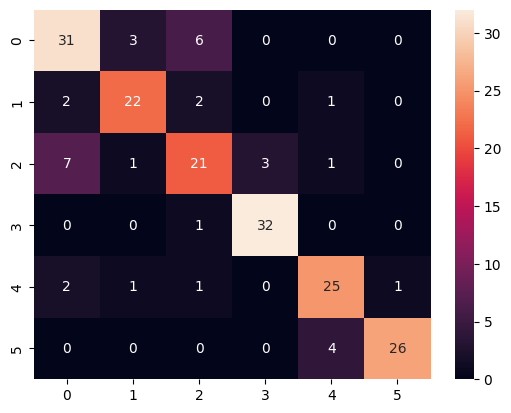

In [4]:
# 3. Decision Tree
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
evaluate_model(dt_model, X_test, y_test)

Accuracy: 0.9533678756476683
Precision: 0.9537098664469966
Recall: 0.9533678756476683
F1 Score: 0.9532539273784159
Confusion Matrix:
 [[40  0  0  0  0  0]
 [ 0 26  0  0  1  0]
 [ 2  0 30  1  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  0  0 28  2]
 [ 0  0  0  0  1 29]]


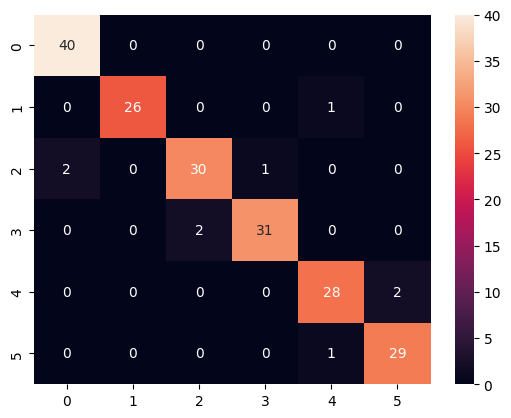

In [5]:
# 4. Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
evaluate_model(rf_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-03-21 17:42:31.896022: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2025-03-21 17:42:31.896052: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-03-21 17:42:31.896058: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-03-21 17:42:31.896074: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-21 17:42:31.896083: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_fa

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8956 - loss: 0.3714
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.9015544041450777
Precision: 0.9051006009146919
Recall: 0.9015544041450777
F1 Score: 0.9008450097521146
Confusion Matrix:
 [[37  0  3  0  0  0]
 [ 3 21  0  0  1  2]
 [ 0  2 30  1  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  0  0 30  0]
 [ 0  0  0  0  5 25]]


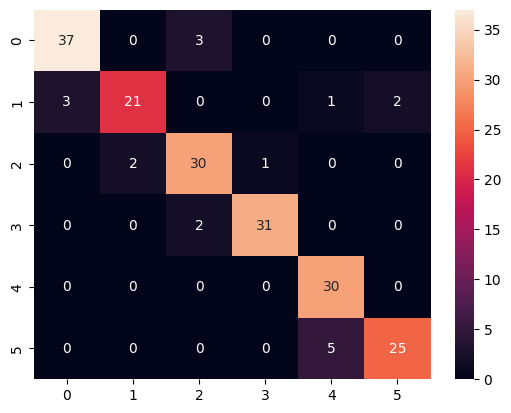

In [6]:
# 5. Artificial Neural Network

def evaluate_model(model, X_test, y_test, labels=None):
    # Handle ANN/CNN differently — check if output is probabilistic
    y_pred = model.predict(X_test)
    if len(y_pred.shape) > 1 and y_pred.shape[1] > 1:
        y_pred = np.argmax(y_pred, axis=1)  # Convert softmax output to class labels
    
    # Compute metrics
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))
    
    # Ensure confusion matrix includes all labels even if missing in predictions
    cm = confusion_matrix(y_test, y_pred, labels=labels if labels else np.unique(y_test))
    print("Confusion Matrix:\n", cm)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.show()

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train, y_train, epochs=20, batch_size=16, verbose=0)
ann_eval = ann_model.evaluate(X_test, y_test)
y_pred_ann = np.argmax(ann_model.predict(X_test), axis=1)
evaluate_model(ann_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9257 - loss: 0.3481
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.9326424870466321
Precision: 0.9366405830031937
Recall: 0.9326424870466321
F1 Score: 0.933291836267922
Confusion Matrix:
 [[36  0  3  0  0  1]
 [ 0 26  0  0  1  0]
 [ 0  1 31  1  0  0]
 [ 0  0  3 30  0  0]
 [ 0  0  0  0 29  1]
 [ 0  0  0  0  2 28]]


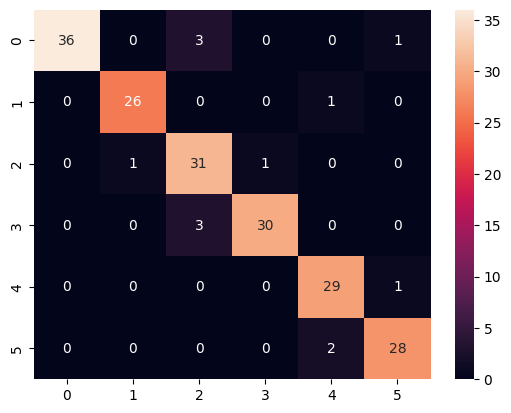

In [7]:
# 6. Convolutional Neural Network (1D for feature data)
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential([
    Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.fit(X_train_cnn, y_train, epochs=20, batch_size=16, verbose=0)
cnn_eval = cnn_model.evaluate(X_test_cnn, y_test)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)
evaluate_model(cnn_model, X_test_cnn, y_test)